# EDA 03 — Djinni job postings and candidate profiles (Problem 3 data)

**Datasets:** `lang-uk/recruitment-dataset-job-descriptions-english` (141,897 IT job postings from the Djinni
job board, Ukraine, 2020–2023) and `lang-uk/recruitment-dataset-candidate-profiles-english` (~210k anonymised
CVs), both MIT-licensed. Jobs are the Problem 3 job pool; CVs are the resumes of the labelled evaluation set.
CV texts are PII-scrubbed (e-mails, phones, URLs, handles) before any use.

In [1]:
import json, os, re, collections, random, pathlib
import numpy as np, pandas as pd
import plotly.express as px, plotly.graph_objects as go
os.environ["SMC_SOURCE"] = "notebooks/03_eda_djinni"
from src.utils import viz; viz.setup()
from src.utils.config import ROOT, models_cfg
from src.utils.io import write_json
from src.data import djinni

jobs, jinfo = djinni.load_jobs()
cvs, cinfo = djinni.load_cvs()
print("jobs:", jinfo["rows"], "columns:", jinfo["source_columns"]); print("mapping:", jinfo["mapping"])
print("cvs :", cinfo["rows"], "columns:", cinfo["source_columns"]); print("mapping:", cinfo["mapping"])

jobs: 141897 columns: ['Position', 'Long Description', 'Company Name', 'Exp Years', 'Primary Keyword', 'English Level', 'Published', 'Long Description_lang', 'id', '__index_level_0__']
mapping: {'title': 'Position', 'description': 'Long Description', 'company': 'Company Name', 'category': 'Primary Keyword', 'exp_years': 'Exp Years', 'english_level': 'English Level', 'published': 'Published'}
cvs : 210250 columns: ['Position', 'Moreinfo', 'Looking For', 'Highlights', 'Primary Keyword', 'English Level', 'Experience Years', 'CV', 'CV_lang', 'id', '__index_level_0__']
mapping: {'title': 'Position', 'category': 'Primary Keyword', 'exp_years': 'Experience Years', 'english_level': 'English Level', 'moreinfo': 'Moreinfo', 'looking_for': 'Looking For', 'highlights': 'Highlights', 'cv': 'CV'}


## 1. Schema, record counts, missing values, duplicates

In [2]:
def missing_table(df, cols):
    rows = []
    for c in cols:
        s = df[c]
        empty = s.isna() | (s.astype(str).str.strip() == "")
        rows.append({"field": c, "missing_or_empty": int(empty.sum()), "share": round(float(empty.mean()), 4)})
    return pd.DataFrame(rows)
miss_jobs = missing_table(jobs, ["title", "description", "company", "category", "exp_years", "english_level", "published"])
miss_cvs = missing_table(cvs, ["title", "category", "exp_years", "english_level"])
# the four free-text CV fields were merged into `text` by the loader; their presence flags give the missing shares
miss_cvs = pd.concat([miss_cvs, pd.DataFrame([{"field": f, "missing_or_empty": int((~cvs[f"has_{f}"]).sum()), "share": round(float((~cvs[f"has_{f}"]).mean()), 4)} for f in ["moreinfo", "looking_for", "highlights", "cv"]])], ignore_index=True)
dup_jobs = int(jobs.duplicated(["title", "description"]).sum()); dup_cvs = int(cvs.duplicated(["text"]).sum())
print(f"duplicate job postings (same title+description): {dup_jobs:,} ({dup_jobs/len(jobs):.1%}) | duplicate CV texts: {dup_cvs:,} ({dup_cvs/len(cvs):.1%})")
pd.concat([miss_jobs.assign(table="jobs"), miss_cvs.assign(table="cvs")])

duplicate job postings (same title+description): 0 (0.0%) | duplicate CV texts: 0 (0.0%)


,field,missing_or_empty,share,table
0,title,0,0.0000,jobs
1,description,0,0.0000,jobs
2,company,0,0.0000,jobs
3,category,0,0.0000,jobs
4,exp_years,0,0.0000,jobs
5,english_level,7539,0.0531,jobs
6,published,0,0.0000,jobs
0,title,0,0.0000,cvs
1,category,43,0.0002,cvs
2,exp_years,0,0.0000,cvs


In [3]:
m = pd.concat([miss_jobs.assign(table="job postings"), miss_cvs.assign(table="candidate profiles")])
fig = px.bar(m, x="field", y="share", color="table", barmode="group", facet_col="table", facet_col_spacing=0.08, text=m["share"].map(lambda v: f"{v:.0%}"),
             title="Missing or empty values per field")
fig.update_traces(textposition="outside"); fig.update_xaxes(matches=None); fig.update_layout(yaxis_tickformat=".0%", showlegend=False, yaxis_title="share of records")
viz.save_fig(fig, "eda03_missing_values", "Djinni: share of missing/empty values per field for job postings and candidate profiles (CV free-text fields such as 'Looking For' and 'Highlights' are often empty).")
fig

## 2. Text length distributions (tokens ≈ whitespace-split words)

In [4]:
jobs["n_words"] = jobs["description"].str.count(r"\S+").astype("int32")
cvs["n_words"] = cvs["text"].str.count(r"\S+").astype("int32")
print("job description words:", jobs["n_words"].describe().round(1).to_dict())
print("cv words            :", cvs["n_words"].describe().round(1).to_dict())
min_chars = 300
print(f"CVs shorter than {min_chars} characters (excluded from the labelled set): {(cvs['n_chars'] < min_chars).mean():.1%}")
ld = pd.concat([pd.DataFrame({"words": jobs["n_words"].sample(60000, random_state=42).clip(upper=1500), "type": "job posting"}), pd.DataFrame({"words": cvs["n_words"].sample(60000, random_state=42).clip(upper=1500), "type": "candidate profile"})])
fig = px.histogram(ld, x="words", color="type", barmode="overlay", opacity=0.7, nbins=75, title="Length of job postings vs candidate profiles (words, clipped at 1,500)")
fig.update_layout(yaxis_title="records", bargap=0.05)
viz.save_fig(fig, "eda03_text_length", "Djinni text lengths: job postings are typically 150–400 words; CVs are much more variable, with a long tail of multi-page profiles and a spike of one-liners.")
fig

job description words: {'count': 141897.0, 'mean': 259.9, 'std': 142.5, 'min': 6.0, '25%': 159.0, '50%': 234.0, '75%': 330.0, 'max': 2022.0}
cv words            : {'count': 210250.0, 'mean': 282.8, 'std': 197.7, 'min': 5.0, '25%': 140.0, '50%': 227.0, '75%': 369.0, 'max': 2132.0}
CVs shorter than 300 characters (excluded from the labelled set): 0.9%


## 3. Category (Primary Keyword), experience and English-level distributions

In [5]:
top_cats = jobs["category"].value_counts().head(20)
cv_cats = cvs["category"].value_counts()
sd = pd.DataFrame({"category": top_cats.index, "job postings": top_cats.values, "candidate profiles": [int(cv_cats.get(c, 0)) for c in top_cats.index]})
sd["cvs per posting"] = sd["candidate profiles"] / sd["job postings"]
sd

,category,job postings,candidate profiles,cvs per posting
0,JavaScript,17903,33980,1.898006
1,Java,8712,11463,1.315771
2,DevOps,7979,4120,0.516355
3,.NET,7826,9388,1.199591
4,Other,7536,5395,0.715897
5,QA Automation,7047,5756,0.816801
6,Marketing,6933,8984,1.295832
7,QA,6774,25089,3.703720
8,Node.js,6416,4896,0.763092
9,PHP,5740,6947,1.210279


In [6]:
fig = px.bar(sd.melt(id_vars="category", value_vars=["job postings", "candidate profiles"], var_name="side", value_name="count"),
             x="category", y="count", color="side", barmode="group", title="Supply vs demand: candidate profiles and job postings per category (top 20 job categories)")
fig.update_layout(xaxis_title="", yaxis_title="records")
viz.save_fig(fig, "eda03_supply_demand", "Supply–demand by category: number of candidate profiles vs job postings for the 20 largest job categories on Djinni.")
fig

In [7]:
hm = sd.set_index("category")[["job postings", "candidate profiles", "cvs per posting"]].copy()
z = np.vstack([ (hm["job postings"] / hm["job postings"].max()).values, (hm["candidate profiles"] / hm["candidate profiles"].max()).values, (hm["cvs per posting"] / hm["cvs per posting"].max()).values ])
fig = go.Figure(go.Heatmap(z=z, x=hm.index, y=["job postings (rel.)", "candidate profiles (rel.)", "CVs per posting (rel.)"], colorscale=[[i/(len(viz.SEQ_BLUE)-1), c] for i, c in enumerate(viz.SEQ_BLUE)],
                           text=np.vstack([hm["job postings"].values, hm["candidate profiles"].values, hm["cvs per posting"].round(1).values]), texttemplate="%{text}", showscale=False))
fig.update_layout(title="Supply–demand heatmap per category (each row scaled to its maximum)", height=360)
viz.save_fig(fig, "eda03_supply_demand_heatmap", "Supply–demand heatmap: relative job postings, candidate profiles and CVs-per-posting ratio per category — where competition for a job is highest.", height=360)
fig

In [8]:
ex = pd.concat([pd.DataFrame({"years": jobs["exp_years_num"], "type": "job posting (required)"}), pd.DataFrame({"years": cvs["exp_years_num"], "type": "candidate profile (has)"})]).dropna()
fig = px.histogram(ex[ex["years"] <= 15], x="years", color="type", barmode="group", nbins=16, title="Years of experience: required by postings vs reported in profiles")
fig.update_layout(xaxis_title="years", yaxis_title="records")
viz.save_fig(fig, "eda03_experience_years", "Years of experience required by postings vs reported by candidates — postings cluster at 1–3 years, profiles have a longer tail.")
en = pd.concat([pd.DataFrame({"level": jobs["english_level"], "type": "job posting"}), pd.DataFrame({"level": cvs["english_level"], "type": "candidate profile"})]).dropna()
en = en[en["level"].astype(str).str.strip() != ""]
enc = en.groupby(["type", "level"]).size().reset_index(name="n")
enc["share"] = enc["n"] / enc.groupby("type")["n"].transform("sum")
fig2 = px.bar(enc, x="level", y="share", color="type", barmode="group", text=enc["share"].map(lambda v: f"{v:.0%}"), title="English level: required vs reported")
fig2.update_traces(textposition="outside"); fig2.update_layout(yaxis_tickformat=".0%", xaxis_title="", yaxis_title="share")
viz.save_fig(fig2, "eda03_english_level", "English level required by postings vs reported by candidates.")
fig

## 4. Postings per month by category (2020–2023)

In [9]:
jobs["month"] = pd.to_datetime(jobs["published"], errors="coerce", utc=True).dt.to_period("M").astype(str)
top8 = top_cats.head(8).index
pm = jobs[jobs["category"].isin(top8) & (jobs["month"] != "NaT")].groupby(["month", "category"]).size().reset_index(name="postings")
fig = px.line(pm, x="month", y="postings", color="category", title="Job postings per month for the 8 largest categories (2020–2023)")
fig.update_layout(xaxis_title="", yaxis_title="postings")
viz.save_fig(fig, "eda03_postings_per_month", "Monthly job postings per category on Djinni, 2020–2023 — the 2022 collapse and partial recovery are visible in every category.")
fig

/tmp/ipykernel_14498/4092389520.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  jobs["month"] = pd.to_datetime(jobs["published"], errors="coerce", utc=True).dt.to_period("M").astype(str)


## 5. Word clouds per category

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


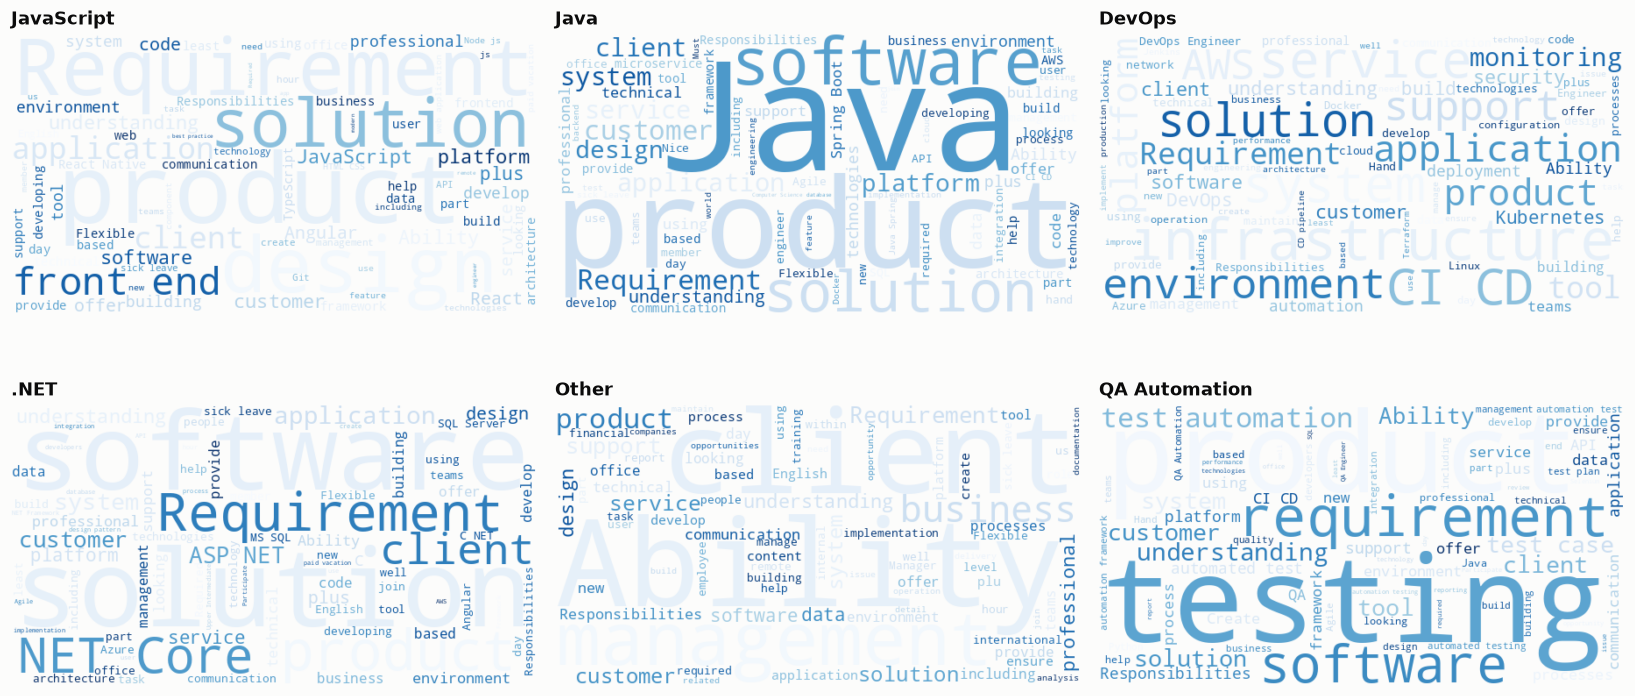

In [10]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
stop = set(STOPWORDS) | {"experience", "work", "will", "team", "company", "project", "projects", "years", "knowledge", "skills", "good", "strong", "working", "development", "developer", "s", "u", "etc", "one"}
cats6 = top_cats.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, c in zip(axes.ravel(), cats6):
    text = " ".join(jobs[jobs["category"] == c]["description"].sample(n=min(800, (jobs["category"] == c).sum()), random_state=42))
    wc = WordCloud(width=600, height=320, background_color=viz.INK["surface"], stopwords=stop, colormap="Blues", max_words=80, random_state=42).generate(text)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(c, fontsize=12, loc="left")
plt.tight_layout()
viz.save_fig(fig, "eda03_wordclouds", "Word clouds of job postings for the six largest categories (800 postings each): the vocabulary differs sharply between stacks.")
plt.show()

## 6. Embedding map (UMAP) of 5,000 postings and 5,000 profiles, and category similarity

In [11]:
import umap
from src.index.embedder import get_text_embedder   # the same text encoder the job index uses (all-MiniLM-L6-v2, 256 tokens)
embedder = get_text_embedder(); enc_path = pathlib.Path(embedder.model_path)
top10 = top_cats.head(10).index.tolist()
js = jobs[jobs["category"].isin(top10)].sample(n=5000, random_state=42)
cs = cvs[cvs["category"].isin(top10) & (cvs["n_chars"] >= 300)].sample(n=5000, random_state=42)
E = np.array(embedder.embed((js["title"] + ". " + js["description"].str[:1200]).tolist() + cs["text"].str[:1500].tolist()))
emb2 = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42).fit_transform(E)
um = pd.DataFrame({"x": emb2[:, 0], "y": emb2[:, 1], "category": js["category"].tolist() + cs["category"].tolist(), "type": ["job posting"] * len(js) + ["candidate profile"] * len(cs),
                   "label": (js["title"].str[:60]).tolist() + (cs["title"].str[:60]).tolist()})
fig = px.scatter(um, x="x", y="y", color="category", facet_col="type", hover_data={"label": True, "x": False, "y": False}, opacity=0.55, title="UMAP of text embeddings: 5,000 postings and 5,000 profiles, coloured by category")
fig.update_traces(marker=dict(size=4, line=dict(width=0)))
fig.update_layout(height=620, xaxis_title="", yaxis_title="")
fig.update_xaxes(showticklabels=False, showgrid=False); fig.update_yaxes(showticklabels=False, showgrid=False)
viz.save_fig(fig, "eda03_umap_market_map", "Market map: UMAP projection of all-MiniLM-L6-v2 embeddings for 5,000 job postings and 5,000 candidate profiles (10 largest categories) — categories form clear clusters, and profiles occupy the same regions as postings.", height=620)
fig

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

/home/claude/venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [12]:
cents = {c: E[np.array(um["category"] == c) & np.array(um["type"] == "job posting")].mean(axis=0) for c in top10}
C = np.array([cents[c] / np.linalg.norm(cents[c]) for c in top10])
S = C @ C.T
fig = go.Figure(go.Heatmap(z=S, x=top10, y=top10, colorscale=[[i/(len(viz.SEQ_BLUE)-1), c] for i, c in enumerate(viz.SEQ_BLUE)], zmin=0.5, zmax=1.0, text=np.round(S, 2), texttemplate="%{text}"))
fig.update_layout(title="Category-to-category similarity (cosine between category centroids of posting embeddings)", height=560)
viz.save_fig(fig, "eda03_category_similarity", "Cosine similarity between category centroids of posting embeddings — used to define 'related' categories when sampling the labelled job pools.", height=560)
fig

## 7. Named entities in job descriptions (spaCy, 2,000 postings)

In [13]:
import spacy
nlp = spacy.load("en_core_web_sm", disable=["lemmatizer", "tagger", "parser", "attribute_ruler"])
sample = jobs["description"].sample(n=2000, random_state=42).str[:2000].tolist()
ents = collections.Counter(); ent_text = collections.defaultdict(collections.Counter)
for doc in nlp.pipe(sample, batch_size=64):
    for e in doc.ents:
        ents[e.label_] += 1
        if e.label_ in ("ORG", "GPE", "PRODUCT"):
            ent_text[e.label_][e.text.strip()] += 1
ed = pd.DataFrame(ents.most_common(10), columns=["label", "entities"])
fig = px.bar(ed, x="label", y="entities", title="Named-entity labels in 2,000 job descriptions (spaCy en_core_web_sm)")
fig.update_layout(xaxis_title="", yaxis_title="entities")
viz.save_fig(fig, "eda03_entities", "spaCy entity labels in Djinni job descriptions: ORG (companies, frameworks mis-typed as organisations), GPE (locations) and DATE dominate.")
print("top ORG:", ent_text["ORG"].most_common(12)); print("top GPE:", ent_text["GPE"].most_common(12))
fig

top ORG: [('JavaScript', 256), ('SQL', 242), ('AWS', 225), ('API', 219), ('CI', 195), ('UI', 193), ('QA', 175), ('CSS', 168), ('DevOps', 140), ('Android', 122), ('TypeScript', 113), ('HTML', 111)]
top GPE: [('React', 171), ('Ukraine', 146), ('US', 140), ('NoSQL', 76), ('USA', 60), ('Linux', 57), ('UK', 56), ('PostgreSQL', 53), ('Node.js', 49), ('AI', 42), ('Ukrainian', 40), ('Germany', 40)]


## 8. Summary

In [14]:
summary = {
    "rows": {"jobs": int(len(jobs)), "cvs": int(len(cvs))}, "source_columns": {"jobs": jinfo["source_columns"], "cvs": cinfo["source_columns"]},
    "missing": {"jobs": miss_jobs.to_dict("records"), "cvs": miss_cvs.to_dict("records")}, "duplicates": {"jobs": dup_jobs, "cvs": dup_cvs},
    "words": {"jobs_median": float(jobs["n_words"].median()), "cvs_median": float(cvs["n_words"].median()), "cvs_under_300_chars_share": round(float((cvs["n_chars"] < 300).mean()), 4)},
    "top_categories_jobs": top_cats.head(10).to_dict(), "cvs_per_posting_top10": sd.head(10).set_index("category")["cvs per posting"].round(2).to_dict(),
    "pii_removed_total": int(cvs["pii_removed"].sum()) if "pii_removed" in cvs else None, "encoder_for_umap": str(enc_path.name),
    "cvs_with_all_four_fields_share": round(float((cvs["has_moreinfo"] & cvs["has_looking_for"] & cvs["has_highlights"] & cvs["has_cv"]).mean()), 4),
    "category_similarity_top10": {c: {o: round(float(S[i, j]), 3) for j, o in enumerate(top10)} for i, c in enumerate(top10)},
}
write_json(summary, "results/eda/djinni_summary.json")
print(json.dumps({k: v for k, v in summary.items() if k not in ("missing", "source_columns", "category_similarity_top10")}, indent=1))
print(f"""
THREE MOST IMPORTANT FINDINGS
1. {len(jobs):,} postings and {len(cvs):,} profiles, but {(cvs['n_chars']<300).mean():.0%} of profiles are under 300 characters and {dup_jobs/len(jobs):.0%} of postings are exact
   duplicates -> we filter both before building the job index and the labelled set.
2. Supply and demand are unbalanced by category: {sd.iloc[0]['category']} has {sd.iloc[0]['cvs per posting']:.1f} profiles per posting while the median top-20 category has
   {sd['cvs per posting'].median():.1f} -> a matcher must rank within crowded categories, not just pick the category.
3. Categories form clear clusters in embedding space, and adjacent categories ({top10[0]} ~ {max(((S[0,j], top10[j]) for j in range(1,len(top10))))[1]}) are close ->
   'related-category' jobs are a meaningful hard-negative tier in the labelled pools.
""")

{
 "rows": {
  "jobs": 141897,
  "cvs": 210250
 },
 "duplicates": {
  "jobs": 0,
  "cvs": 0
 },
 "words": {
  "jobs_median": 234.0,
  "cvs_median": 227.0,
  "cvs_under_300_chars_share": 0.0087
 },
 "top_categories_jobs": {
  "JavaScript": 17903,
  "Java": 8712,
  "DevOps": 7979,
  ".NET": 7826,
  "Other": 7536,
  "QA Automation": 7047,
  "Marketing": 6933,
  "QA": 6774,
  "Node.js": 6416,
  "PHP": 5740
 },
 "cvs_per_posting_top10": {
  "JavaScript": 1.9,
  "Java": 1.32,
  "DevOps": 0.52,
  ".NET": 1.2,
  "Other": 0.72,
  "QA Automation": 0.82,
  "Marketing": 1.3,
  "QA": 3.7,
  "Node.js": 0.76,
  "PHP": 1.21
 },
 "pii_removed_total": 14830,
 "encoder_for_umap": "all-MiniLM-L6-v2",
 "cvs_with_all_four_fields_share": 0.3407
}

THREE MOST IMPORTANT FINDINGS
1. 141,897 postings and 210,250 profiles, but 1% of profiles are under 300 characters and 0% of postings are exact
   duplicates -> we filter both before building the job index and the labelled set.
2. Supply and demand are unbalanced 